In [14]:
import warnings, pickle, ast, os
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
warnings.filterwarnings("ignore"); os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
NAVY, TEAL, GREY, RED, AMBER = "#0B2545", "#13A89E", "#8D99AE", "#D62839", "#F4A261"

ROOT = Path("..")                                    
RAW_CSV     = ROOT/"data_raw"/"metro_passengers_trips_by_station_monthly_2026-04-10_14-26-01_0001.csv"
MASTER_CSV  = ROOT/"data_processed"/"metro_trips_clean.csv"
MODEL_CSV   = ROOT/"data_processed"/"metro_trips_model_ready.csv"
SARIMA_V1   = ROOT/"docs"/"sarima_results_summary.csv"
SARIMA_CSV  = ROOT/"docs"/"sarima_results_final.csv"
LSTM_CSV    = ROOT/"docs"/"lstm_results_summary.csv"
COMP_CSV    = ROOT/"docs"/"sarima_vs_lstm_comparison.csv"
SARIMA_DIR, LSTM_DIR = ROOT/"models"/"sarima", ROOT/"models"/"lstm"
FIG = ROOT/"docs"/"Evidence"/"ch5"/"figures"; TAB = ROOT/"docs"/"Evidence"/"ch5"/"tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
HOLDOUT, WINDOW = 6, 12
MONTHS = {'Jan':1,'Feb':2,'Mar':3,'Apr':4,'May':5,'Jun':6,'Jul':7,'Aug':8,'Sep':9,'Oct':10,'Nov':11,'Dec':12}

def save_fig(fig, label, slug):
    p = FIG/f"{label.replace(' ', '_')}_{slug}.png"; fig.savefig(p, bbox_inches="tight", facecolor="white")
    print("saved", p); plt.show()
def save_table(df, label, slug):
    stem = TAB/f"{label.replace(' ', '_')}_{slug}"
    df.to_csv(str(stem) + ".csv", index=False); df.to_html(str(stem) + ".html", index=False)   # NB: with_suffix would clobber the ".1" in "Table_5.1_..."
    print("saved", stem.name); return df
def safe(name): return name.replace('/', '_').replace(' ', '_')          # same rule as notebooks 04/05
def mape(a, f): a, f = np.asarray(a, float), np.asarray(f, float); return float(np.mean(np.abs((a - f) / a)) * 100)

master = pd.read_csv(MASTER_CSV, parse_dates=["date"]).sort_values(["metro_station", "date"])
model  = pd.read_csv(MODEL_CSV,  parse_dates=["date"]).sort_values(["metro_station", "date"])
# ---- integrity checks against what the notebooks reported ----
print("master rows:", len(master), "(expect 4,889) | stations:", master.metro_station.nunique(), "(expect 53)")
print("model-ready rows:", len(model), "(expect 3,405) | window:", model.date.min().date(), "to", model.date.max().date())
assert model.date.max() == pd.Timestamp("2023-08-01"), "model_ready is not the final Aug-2023 window - re-run notebook 07 cell 10"
assert len(model) == 3405

def full_name(short):
    hits = [s for s in model.metro_station.unique() if short.lower() in s.lower()]
    assert len(hits) == 1, f"'{short}' matched {hits}"; return hits[0]
def get_series(name, clean=True):
    """Exactly as notebooks 04/05: asfreq('MS'), then linear interpolation + bfill/ffill."""
    s = model[model.metro_station == full_name(name)].set_index("date")["trips"].asfreq("MS")
    return s.interpolate("linear").bfill().ffill() if clean else s
print(get_series("BurJuman").shape, "(expect (68,))")

master rows: 4889 (expect 4,889) | stations: 53 (expect 53)
model-ready rows: 3405 (expect 3,405) | window: 2018-01-01 to 2023-08-01
(68,) (expect (68,))


## Section A - Tables


In [15]:
# TABLE 5.1 - Data cleaning summary (notebooks 01, 04, 07)
t51 = pd.DataFrame([
 ["Raw Dubai Pulse extract (loaded 10 Apr 2026)", "33,776", "57 labels", "613 distinct load timestamps; 28,834 duplicate station-month rows (NB01 cells 1, 3, 4)"],
 ["One row per station-month, latest load kept", "4,942 (derived)", "57 labels", "1,113 conflicting groups resolved by most recent load_timestamp (NB01 cell 7)"],
 ["Exclude identical-timestamp conflicts", "4,889", "57 labels", "53 groups, all Dec 2023; max/min ratio median 2.78, IQR 2.72-2.84, maximum 6.88 (NB01 cells 7-10)"],
 ["Merge four station renames", "4,889", "53 stations", "No new duplicates created by the merge (NB01 cells 15-16)"],
 ["Restrict to validated window (Jan 2018 - Aug 2023)", "3,405", "53 stations", "Cutoff 2023-09-01; Sep-Nov 2023 absent in raw file, Dec 2023 excluded (NB04 cells 3-5, NB07 cell 10)"],
], columns=["Stage", "Rows", "Stations", "Note"])
save_table(t51, "Table 5.1", "data_cleaning_summary")

saved Table_5.1_data_cleaning_summary


,Stage,Rows,Stations,Note
0,Raw Dubai Pulse extract (loaded 10 Apr 2026),"33,776",57 labels,"613 distinct load timestamps; 28,834 duplicate..."
1,"One row per station-month, latest load kept","4,942 (derived)",57 labels,"1,113 conflicting groups resolved by most rece..."
2,Exclude identical-timestamp conflicts,"4,889",57 labels,"53 groups, all Dec 2023; max/min ratio median ..."
3,Merge four station renames,"4,889",53 stations,No new duplicates created by the merge (NB01 c...
4,Restrict to validated window (Jan 2018 - Aug 2...,"3,405",53 stations,Cutoff 2023-09-01; Sep-Nov 2023 absent in raw ...


In [16]:
# TABLE 5.2 - Station renames, with the evidence from the data itself (notebook 01 cell 14)
t54 = pd.DataFrame([
 ["Jumeirah Lakes Towers", "DMCC", "Jan-Apr 2018 (4 records)", "from May 2018 (92 records)"],
 ["Sharaf DG", "Mashreq", "Jan 2018-Mar 2020 (27 records)", "from Apr 2020 (69 records)"],
 ["Nakheel Harbour & Tower", "Jabal Ali", "2 records only (to Mar 2020)", "from Feb 2020 (69 records)"],
 ["Palm Deira", "Gold Souq", "Jan 2018-Mar 2020 (26 records)", "from Feb 2020 (70 records)"],
], columns=["Former label", "Current label", "Former label present", "Current label present"])
save_table(t54, "Table 5.2", "station_renames")

saved Table_5.2_station_renames


,Former label,Current label,Former label present,Current label present
0,Jumeirah Lakes Towers,DMCC,Jan-Apr 2018 (4 records),from May 2018 (92 records)
1,Sharaf DG,Mashreq,Jan 2018-Mar 2020 (27 records),from Apr 2020 (69 records)
2,Nakheel Harbour & Tower,Jabal Ali,2 records only (to Mar 2020),from Feb 2020 (69 records)
3,Palm Deira,Gold Souq,Jan 2018-Mar 2020 (26 records),from Feb 2020 (70 records)


In [17]:
# TABLE 5.3 - SARIMA three iterations (notebook 04). NB: v2 statistics cover only the 46 stations where it ran.
t52 = pd.DataFrame([
 ["v1", "4 fixed, structurally diverse configurations; holdout-selected", "53", 7.31, 8.75, "0", "Not a true grid search"],
 ["v2", "auto_arima exhaustive search (stepwise=False); top-5 by AIC; holdout-selected", "46", 8.13, 8.68, "7", "search_failed where NaN gaps existed (e.g. Al Furjan, Discovery Gardens)"],
 ["Final", "Union of 4 fixed + top-5 AIC (up to 9 per station); linear interpolation of gaps", "53", 7.27, 8.20, "0", "7 stations interpolated"],
], columns=["Version", "Approach", "Stations scored", "Median MAPE (%)", "Mean MAPE (%)", "Failed", "Note"])
save_table(t52, "Table 5.3", "sarima_iterations")

saved Table_5.3_sarima_iterations


,Version,Approach,Stations scored,Median MAPE (%),Mean MAPE (%),Failed,Note
0,v1,"4 fixed, structurally diverse configurations; ...",53,7.31,8.75,0,Not a true grid search
1,v2,auto_arima exhaustive search (stepwise=False);...,46,8.13,8.68,7,search_failed where NaN gaps existed (e.g. Al ...
2,Final,Union of 4 fixed + top-5 AIC (up to 9 per stat...,53,7.27,8.20,0,7 stations interpolated


In [24]:
# TABLE 5.4 - Which SARIMA family was selected? (v1 from NB04 cell 15; final computed from the CSV)
def family(row):
    o, so = ast.literal_eval(row.order), ast.literal_eval(row.seasonal_order)
    return "seasonal" if sum(so[:3]) > 0 else ("non-seasonal, d=1" if o[1] == 1 else "non-seasonal, d=0")
sar["family"] = sar.apply(family, axis=1)
t57 = sar.family.value_counts().rename_axis("Family (final selection)").reset_index(name="Stations")
v1 = pd.DataFrame([["v1: nonseasonal_arima111 (1,1,1)", 30], ["v1: nonseasonal_ar1 (1,0,0)", 14],
                   ["v1: seasonal_111_111", 8], ["v1: seasonal_110_110", 1]], columns=["Family (final selection)", "Stations"])
t57 = pd.concat([t57, v1], ignore_index=True)
save_table(t57, "Table 5.4", "sarima_families"); t57

saved Table_5.4_sarima_families


,Family (final selection),Stations
0,"non-seasonal, d=1",26
1,seasonal,23
2,"non-seasonal, d=0",4
3,"v1: nonseasonal_arima111 (1,1,1)",30
4,"v1: nonseasonal_ar1 (1,0,0)",14
5,v1: seasonal_111_111,8
6,v1: seasonal_110_110,1


In [25]:
# TABLE 5.5 - Stations with interpolated months, and stations excluded from LSTM (computed from the CSVs)
t59a = sar.loc[sar.interpolated_months > 0, ["station", "interpolated_months", "MAPE_sarima"]].sort_values("interpolated_months", ascending=False)
t59a.columns = ["Station", "Interpolated months", "SARIMA MAPE (%)"]; t59a["SARIMA MAPE (%)"] = t59a["SARIMA MAPE (%)"].round(2)
print(t59a.to_string(index=False))
skipped = comp[comp.MAPE_lstm.isna()][["station", "MAPE_sarima"]]
print("\nExcluded from LSTM (insufficient history):"); print(skipped.round(2).to_string(index=False))
save_table(t59a, "Table 5.5", "interpolated_stations")

                            Station  Interpolated months  SARIMA MAPE (%)
            Jabal Ali Metro Station                   25             6.84
Dubai Investment Park Metro Station                    4            13.37
    Discovery Gardens Metro Station                    4             7.07
            Al Furjan Metro Station                    2             8.07
                 EXPO Metro Station                    2            29.65
          The Gardens Metro Station                    2             7.53
Jumeirah Golf Estates Metro Station                    1            10.93

Excluded from LSTM (insufficient history):
                        station  MAPE_sarima
Discovery Gardens Metro Station         7.07
      The Gardens Metro Station         7.53
saved Table_5.5_interpolated_stations


,Station,Interpolated months,SARIMA MAPE (%)
39,Jabal Ali Metro Station,25,6.84
28,Dubai Investment Park Metro Station,4,13.37
24,Discovery Gardens Metro Station,4,7.07
6,Al Furjan Metro Station,2,8.07
29,EXPO Metro Station,2,29.65
49,The Gardens Metro Station,2,7.53
40,Jumeirah Golf Estates Metro Station,1,10.93


In [26]:
# TABLE 5.6 - BurJuman: AIC versus holdout accuracy (notebook 04 cells 8-11)
t58 = pd.DataFrame([
 ["pmdarima, full series (68 obs)", "auto (0,1,0)(0,0,0,12)", 1802.9, "-", "stepwise AIC winner"],
 ["pmdarima, full series (68 obs)", "forced (1,1,1)(1,1,1,12)", 1509.6, "-", "much lower AIC"],
 ["statsmodels, train only (62 obs)", "(1,0,0)(0,0,0,12)", 1645.0, 5.10, "holdout MAE 86,791"],
 ["statsmodels, train only (62 obs)", "(1,1,1)(1,1,1,12)", 964.4, 12.10, "holdout MAE 191,695"],
 ["statsmodels, train only (62 obs)", "(1,1,0)(1,1,0,12)", 1000.8, 19.43, "holdout MAE 309,488"],
 ["v1 selection (holdout)", "(1,1,1)(0,0,0,12)", "-", 4.8, "chosen for BurJuman"],
], columns=["Source", "Configuration", "AIC", "Holdout MAPE (%)", "Note"])
print("CAUTION: AIC is not comparable across models with different orders of differencing (d, D) - the seasonal models")
print("above difference the series twice; say 'AIC is not a reliable guide to forecast accuracy here', not 'AIC overfits'.")
save_table(t58, "Table 5.6", "burjuman_aic_vs_holdout")

CAUTION: AIC is not comparable across models with different orders of differencing (d, D) - the seasonal models
above difference the series twice; say 'AIC is not a reliable guide to forecast accuracy here', not 'AIC overfits'.
saved Table_5.6_burjuman_aic_vs_holdout


,Source,Configuration,AIC,Holdout MAPE (%),Note
0,"pmdarima, full series (68 obs)","auto (0,1,0)(0,0,0,12)",1802.9,-,stepwise AIC winner
1,"pmdarima, full series (68 obs)","forced (1,1,1)(1,1,1,12)",1509.6,-,much lower AIC
2,"statsmodels, train only (62 obs)","(1,0,0)(0,0,0,12)",1645.0,5.1,"holdout MAE 86,791"
3,"statsmodels, train only (62 obs)","(1,1,1)(1,1,1,12)",964.4,12.1,"holdout MAE 191,695"
4,"statsmodels, train only (62 obs)","(1,1,0)(1,1,0,12)",1000.8,19.43,"holdout MAE 309,488"
5,v1 selection (holdout),"(1,1,1)(0,0,0,12)",-,4.8,chosen for BurJuman


In [27]:
# TABLE 5.8 - LSTM run-to-run variability, BurJuman (notebook 05; runs were NOT seeded, so re-runs will differ)
t53 = pd.DataFrame([
 ["Single run (NB05 cell 3)", 1, "9.1", "-"],
 ["Five independent runs (NB05 cell 4)", 5, "17.8, 14.2, 9.0, 25.1, 9.9", "mean 15.2, sd 5.9"],
 ["3-run prediction average, function test (NB05 cell 5)", 3, "8.5", "sd across runs 2.5"],
 ["3-run prediction average, production run (NB05 cell 6)", 3, "9.7", "sd across runs 2.3"],
], columns=["Protocol", "Runs", "MAPE (%)", "Spread"])
save_table(t53, "Table 5.8", "lstm_multirun")

saved Table_5.8_lstm_multirun


,Protocol,Runs,MAPE (%),Spread
0,Single run (NB05 cell 3),1,9.1,-
1,Five independent runs (NB05 cell 4),5,"17.8, 14.2, 9.0, 25.1, 9.9","mean 15.2, sd 5.9"
2,"3-run prediction average, function test (NB05 ...",3,8.5,sd across runs 2.5
3,"3-run prediction average, production run (NB05...",3,9.7,sd across runs 2.3


In [28]:
# TABLE 5.9 - Largest LSTM errors (notebook 05 cells 6-10)
t55 = pd.DataFrame([
 ["EXPO", 435.1, 74.1, "Not yet diagnosed - run the EXPO diagnostic cell in Section B. Series peaks at 2,275,405 (Mar 2022) then falls sharply."],
 ["Energy", 90.4, 5.4, "Debug run (NB05 cell 10): predictions rose from ~51k to ~104k while actuals fell from 40.9k to 30.6k, although every input window held actual values."],
 ["Jumeirah Golf Estates", 61.2, 8.3, "Not investigated further (lowest-volume station)."],
 ["Nakheel", 35.9, 11.6, "Not investigated further; highest run-to-run spread."],
], columns=["Station", "LSTM MAPE (%)", "sd across runs", "Diagnosis (evidence)"])
save_table(t55, "Table 5.9", "lstm_extreme_errors")

saved Table_5.9_lstm_extreme_errors


,Station,LSTM MAPE (%),sd across runs,Diagnosis (evidence)
0,EXPO,435.1,74.1,Not yet diagnosed - run the EXPO diagnostic ce...
1,Energy,90.4,5.4,Debug run (NB05 cell 10): predictions rose fro...
2,Jumeirah Golf Estates,61.2,8.3,Not investigated further (lowest-volume station).
3,Nakheel,35.9,11.6,Not investigated further; highest run-to-run s...


In [30]:
# TABLE 5.10 - Headline results, recomputed from the CSVs and compared with notebook 06
sar, lst = pd.read_csv(SARIMA_CSV), pd.read_csv(LSTM_CSV)
comp = sar[["station","order","seasonal_order","MAPE_sarima","RMSE_sarima","MAE_sarima","interpolated_months"]].merge(
        lst[["station","MAPE_lstm","RMSE_lstm","MAE_lstm","std_across_runs"]], on="station", how="outer")
comp["winner"] = np.where(comp.MAPE_lstm.isna(), "SARIMA (LSTM insufficient data)",
                  np.where(comp.MAPE_sarima < comp.MAPE_lstm, "SARIMA", "LSTM"))
assert comp.station.nunique() == 53 and comp.MAPE_sarima.notna().all(), "station-name mismatch between result files"
w = comp.winner.value_counts()
print(w.to_string())
t56 = pd.DataFrame([
 ["Stations modelled", f"{comp.MAPE_sarima.notna().sum()} of 53", f"{comp.MAPE_lstm.notna().sum()} of 53 (Discovery Gardens, The Gardens: 40 months < 42 minimum)"],
 ["Median MAPE (%)", round(comp.MAPE_sarima.median(), 2), round(comp.MAPE_lstm.median(), 2)],
 ["Mean MAPE (%)", round(comp.MAPE_sarima.mean(), 2), f"{comp.MAPE_lstm.mean():.2f} (EXPO alone: {comp.loc[comp.station.str.contains('EXPO'), 'MAPE_lstm'].iloc[0]:.1f})"],
 ["Mean RMSE", f"{comp.RMSE_sarima.mean():,.0f}", f"{comp.RMSE_lstm.mean():,.0f}"],
 ["Mean MAE", f"{comp.MAE_sarima.mean():,.0f}", f"{comp.MAE_lstm.mean():,.0f}"],
 ["Stations won", f"{w.get('SARIMA',0)} outright + {w.get('SARIMA (LSTM insufficient data)',0)} by default", f"{w.get('LSTM',0)}"],
], columns=["Measure", "SARIMA", "LSTM"])
save_table(t56, "Table 5.10", "headline_results")
print("\nLSTM wins:"); print(comp[comp.winner == "LSTM"][["station","MAPE_sarima","MAPE_lstm"]].round(2).to_string(index=False))

winner
SARIMA                             47
LSTM                                4
SARIMA (LSTM insufficient data)     2
saved Table_5.10_headline_results

LSTM wins:
                            station  MAPE_sarima  MAPE_lstm
Abu Baker Al Siddique Metro Station         7.27       6.39
Dubai Investment Park Metro Station        13.37      12.44
             Etisalat Metro Station         7.87       6.14
          Ibn Battuta Metro Station         9.62       7.78


In [31]:
# TABLE 5.11 - Dashboard features mapped to requirements and evidence.
t511 = pd.DataFrame([
 ["53-station schematic map", "FR1", "Figure 5.14"], ["Click or dropdown station selection", "FR2", "Figure 5.14"],
 ["Historical ridership view", "FR3", "Figure 5.14"], ["1-12 month forecast horizon", "FR4", "Figure 5.14"],
 ["SARIMA/LSTM toggle", "FR5", "Figure 5.14"], ["Confidence interval (SARIMA)", "FR6", "Figure 5.14"],
 ["Recommendation badge from holdout MAPE", "FR7", "Figure 5.14"], ["Sortable comparison table", "FR8", "Figure 5.16"],
 ["Insights tab", "FR9", "Figure 5.17"], ["MAPE distribution (box plot)", "FR10", "Figure 5.16"],
 ["Graceful LSTM fallback", "NFR3", "Figure 5.15"], ["Models and data pre-loaded at start-up", "NFR5", "Code Snippet 5.5"],
 ["No horizontal scroll at 1366 x 768", "NFR4", "Not yet formally tested (Chapter 6)"], ["Map legible at 1280 px and above", "NFR6", "Not yet formally tested (Chapter 6)"],
], columns=["Dashboard feature", "Requirement", "Evidence"])
save_table(t511, "Table 5.11", "dashboard_features")

saved Table_5.11_dashboard_features


,Dashboard feature,Requirement,Evidence
0,53-station schematic map,FR1,Figure 5.14
1,Click or dropdown station selection,FR2,Figure 5.14
2,Historical ridership view,FR3,Figure 5.14
3,1-12 month forecast horizon,FR4,Figure 5.14
4,SARIMA/LSTM toggle,FR5,Figure 5.14
5,Confidence interval (SARIMA),FR6,Figure 5.14
6,Recommendation badge from holdout MAPE,FR7,Figure 5.14
7,Sortable comparison table,FR8,Figure 5.16
8,Insights tab,FR9,Figure 5.17
9,MAPE distribution (box plot),FR10,Figure 5.16


## Section B - Figures
### Figure 5.1 - Before/after cleaning (ADCB)


(33776, 6) (expect (33776, 7))
saved ..\docs\Evidence\ch5\figures\Figure_5.1_before_after_cleaning.png


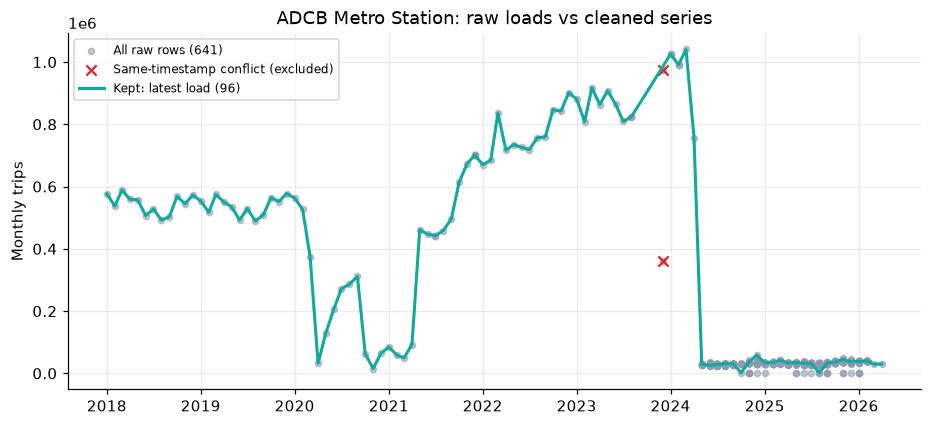

In [32]:
raw = pd.read_csv(RAW_CSV)
raw["metro_station"] = raw["metro_station"].str.replace(r"\s+", " ", regex=True).str.strip()
raw["date"] = pd.to_datetime(dict(year=raw["year"], month=raw["month"].map(MONTHS), day=1))
raw["load_timestamp"] = pd.to_datetime(raw["load_timestamp"])
print(raw.shape, "(expect (33776, 7))")
demo = "ADCB Metro Station"
r = raw[raw.metro_station == demo].copy()
conf_keys = set(r.groupby("date").filter(lambda g: g.trips.nunique() > 1 and g.load_timestamp.nunique() == 1).date)
kept = r.sort_values("load_timestamp").drop_duplicates("date", keep="last")
kept = kept[~kept.date.isin(conf_keys)].sort_values("date")
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.scatter(r.date, r.trips, s=16, c=GREY, alpha=.55, label=f"All raw rows ({len(r)})")
ax.scatter(r[r.date.isin(conf_keys)].date, r[r.date.isin(conf_keys)].trips, marker="x", c=RED, s=45, label="Same-timestamp conflict (excluded)")
ax.plot(kept.date, kept.trips, c=TEAL, lw=2, label=f"Kept: latest load ({len(kept)})")
ax.set(title=f"{demo}: raw loads vs cleaned series", ylabel="Monthly trips"); ax.legend(fontsize=8)
save_fig(fig, "Figure 5.1", "before_after_cleaning")

### Figure 5.2 - System-wide trips: collapse point, gap and validated window


saved ..\docs\Evidence\ch5\figures\Figure_5.2_collapse_investigation.png


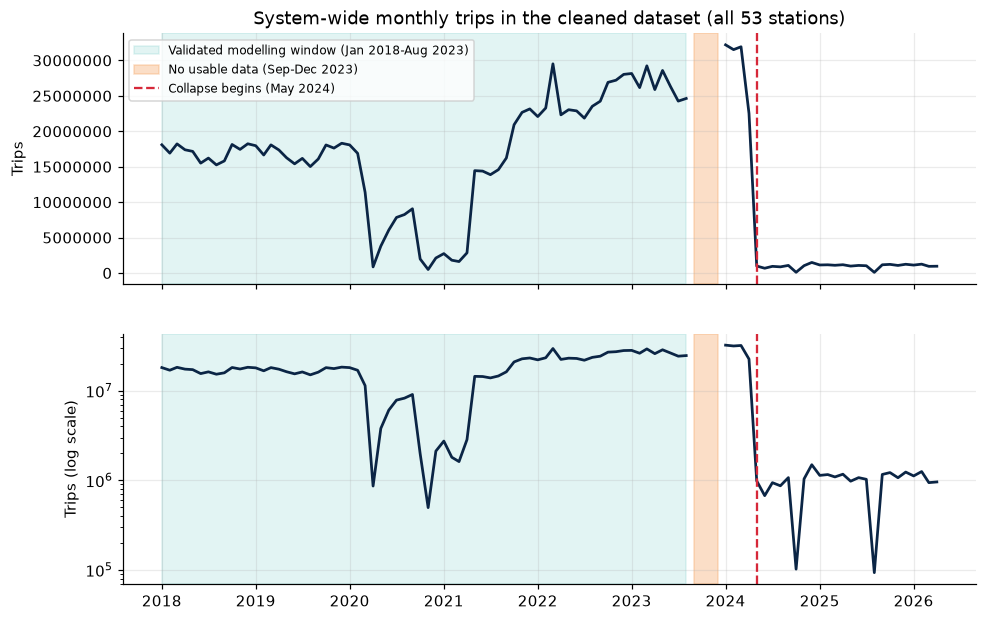

In [33]:
sysm = master.groupby("date")["trips"].sum().asfreq("MS")
fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
for ax, log in zip(axes, [False, True]):
    ax.plot(sysm.index, sysm.values, c=NAVY, lw=1.8)
    ax.axvspan(pd.Timestamp("2018-01-01"), pd.Timestamp("2023-08-01"), color=TEAL, alpha=.12, label="Validated modelling window (Jan 2018-Aug 2023)")
    ax.axvspan(pd.Timestamp("2023-09-01"), pd.Timestamp("2023-12-01"), color=AMBER, alpha=.35, label="No usable data (Sep-Dec 2023)")
    ax.axvline(pd.Timestamp("2024-05-01"), c=RED, ls="--", label="Collapse begins (May 2024)")
    if log: ax.set_yscale("log"); ax.set_ylabel("Trips (log scale)")
    else: ax.set_ylabel("Trips"); ax.legend(loc="upper left", fontsize=8); ax.ticklabel_format(axis="y", style="plain")
axes[0].set_title("System-wide monthly trips in the cleaned dataset (all 53 stations)")
save_fig(fig, "Figure 5.2", "collapse_investigation")

**Supporting numbers for 5.1.1** - reproducing notebook 03 cells 2-8 exactly, plus one extra robustness check (clearly labelled).

In [34]:
import calendar
print("Stations present each month from Jan 2024:", master[master.date >= "2024-01-01"].groupby("date").metro_station.nunique().unique())
b = master[master.date == "2024-04-01"].set_index("metro_station").trips; a = master[master.date == "2024-05-01"].set_index("metro_station").trips
ratio = (b / a).dropna()
print(f"Apr->May 2024 ratio: median {ratio.median():.1f}, range {ratio.min():.1f}-{ratio.max():.1f}, n={len(ratio)}")
post = master[master.date >= "2024-05-01"].copy()
post["weekdays"] = post.date.apply(lambda d: sum(1 for day in pd.date_range(d, periods=calendar.monthrange(d.year, d.month)[1]) if day.weekday() in [6, 0, 1, 2, 3]))  # Sun-Thu
adcb = post[post.metro_station == "ADCB Metro Station"]
print("ADCB: corr(trips, Sun-Thu weekdays in month) =", round(adcb.trips.corr(adcb.weekdays), 2), "(your NB03 value: -0.07, ONE station)")
per_stn = post.groupby("metro_station").apply(lambda g: g.trips.corr(g.weekdays))
print("EXTRA CHECK - same correlation for all 53 stations: median", round(per_stn.median(), 2), "| range", round(per_stn.min(), 2), "to", round(per_stn.max(), 2))
rec = master[master.date >= "2024-01-01"]
print("Distinct load timestamps since Jan 2024:", rec.load_timestamp.nunique(), "| rows per load (min/max):", rec.groupby("load_timestamp").size().min(), rec.groupby("load_timestamp").size().max())
for m_, lab in [("2024-10-01", "Oct 2024"), ("2025-08-01", "Aug 2025"), ("2025-01-01", "Jan 2025 (normal)")]:
    x = master[master.date == m_].trips; print(f"{lab}: mean {x.mean():,.0f} | median {x.median():,.0f}")

Stations present each month from Jan 2024: [53]
Apr->May 2024 ratio: median 23.1, range 12.2-44.7, n=53
ADCB: corr(trips, Sun-Thu weekdays in month) = -0.07 (your NB03 value: -0.07, ONE station)
EXTRA CHECK - same correlation for all 53 stations: median 0.02 | range -0.27 to 0.26
Distinct load timestamps since Jan 2024: 28 | rows per load (min/max): 53 53
Oct 2024: mean 1,926 | median 1,409
Aug 2025: mean 1,759 | median 1,141
Jan 2025 (normal): mean 21,409 | median 18,217


### Figure 5.3 - Six-station sample (same stations as in EDA stage (`eda_08_diverse_sample.png`))


saved ..\docs\Evidence\ch5\figures\Figure_5.3_six_station_sample.png


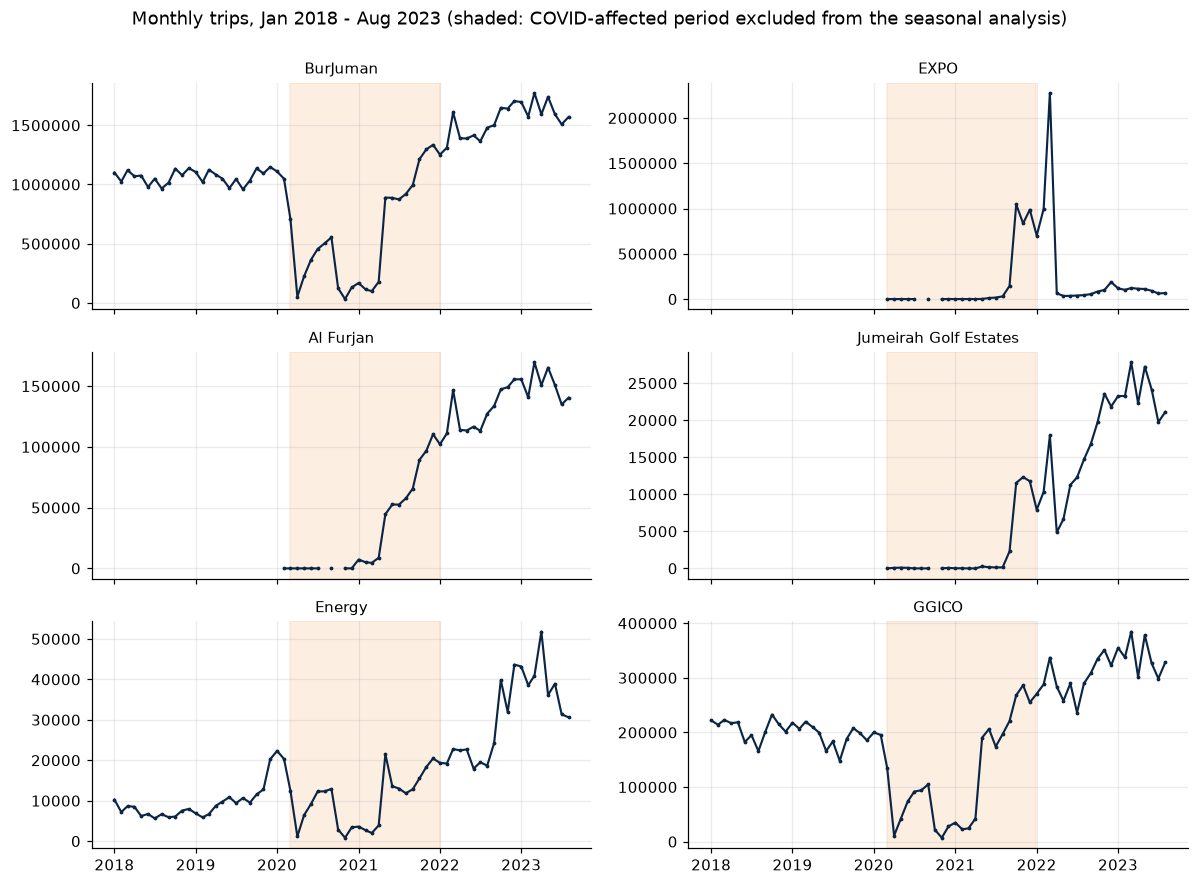

In [35]:
sample = ["BurJuman", "EXPO", "Al Furjan", "Jumeirah Golf Estates", "Energy", "GGICO"]
fig, axes = plt.subplots(3, 2, figsize=(11, 8), sharex=True)
for ax, nm in zip(axes.ravel(), sample):
    s = get_series(nm, clean=False)
    ax.plot(s.index, s.values, c=NAVY, lw=1.4, marker=".", ms=3)
    ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-31"), color=AMBER, alpha=.18)
    ax.set_title(full_name(nm).replace(" Metro Station", ""), fontsize=10); ax.ticklabel_format(axis="y", style="plain")
fig.suptitle("Monthly trips, Jan 2018 - Aug 2023 (shaded: COVID-affected period excluded from the seasonal analysis)", y=1.0)
fig.tight_layout(); save_fig(fig, "Figure 5.3", "six_station_sample")

### Figure 5.4 - Normalised seasonal pattern (Note: COVID months excluded, station-mean normalisation, 12+ months, EXPO excluded)


Median index by month: {1: 0.946, 2: 0.903, 3: 1.13, 4: 0.984, 5: 0.97, 6: 0.949, 7: 0.927, 8: 0.965, 9: 0.867, 10: 0.969, 11: 0.92, 12: 0.965}
Swing (max-min of monthly mean index): 20.8 percentage points of station mean | peak month 3 | trough month 9
saved ..\docs\Evidence\ch5\figures\Figure_5.4_seasonal_pattern.png


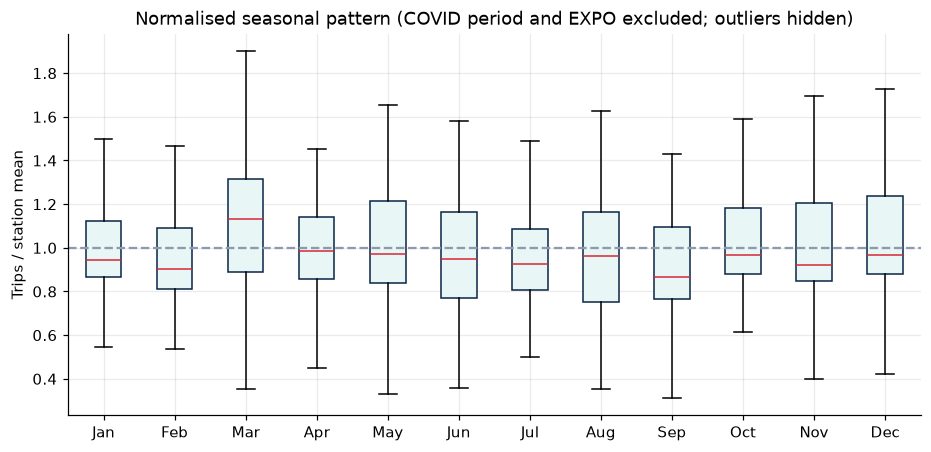

In [36]:
x = model[(model.date < "2020-03-01") | (model.date >= "2022-01-01")].copy()
x = x[~x.metro_station.str.contains("EXPO")]
x = x[x.groupby("metro_station").trips.transform("size") >= 12]
x["norm"] = x.trips / x.groupby("metro_station").trips.transform("mean")
x["m"] = x.date.dt.month
med, mean_ = x.groupby("m").norm.median(), x.groupby("m").norm.mean()
print("Median index by month:", med.round(3).to_dict())
print(f"Swing (max-min of monthly mean index): {(mean_.max() - mean_.min()) * 100:.1f} percentage points of station mean | peak month {mean_.idxmax()} | trough month {mean_.idxmin()}")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot([x[x.m == i].norm for i in range(1, 13)], showfliers=False, patch_artist=True,
           boxprops=dict(facecolor="#E8F6F5", color=NAVY), medianprops=dict(color=RED))
ax.axhline(1, c=GREY, ls="--"); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set(ylabel="Trips / station mean", title="Normalised seasonal pattern (COVID period and EXPO excluded; outliers hidden)")
save_fig(fig, "Figure 5.4", "seasonal_pattern")

### Figure 5.5 - Heatmap: station x calendar month  


saved ..\docs\Evidence\ch5\figures\Figure_5.5_heatmap_station_month.png


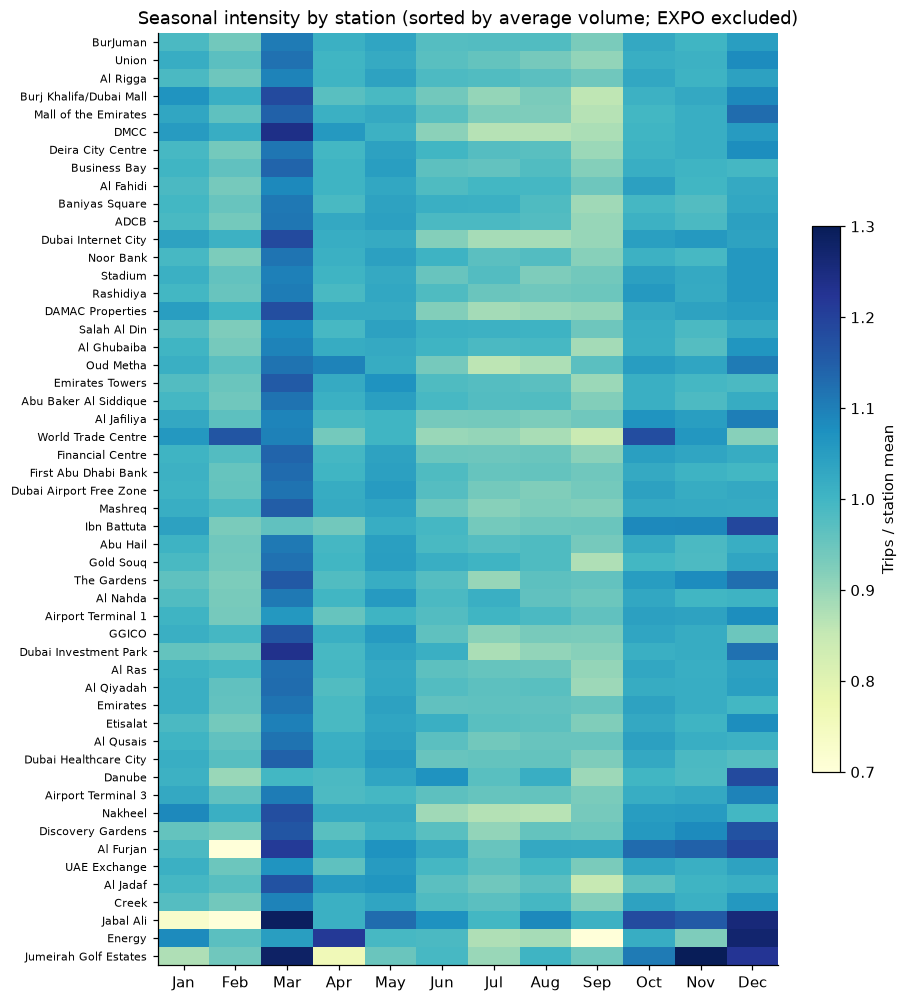

In [37]:
y = model[(model.date < "2020-03-01") | (model.date >= "2022-01-01")].copy()
y = y[~y.metro_station.str.contains("EXPO")]; y = y[y.groupby("metro_station").trips.transform("size") >= 12]
y["norm"] = y.trips / y.groupby("metro_station").trips.transform("mean"); y["m"] = y.date.dt.month
pv = y.pivot_table(index="metro_station", columns="m", values="norm", aggfunc="mean")
order = y.groupby("metro_station").trips.mean().sort_values(ascending=False).index
pv = pv.loc[order]; pv.index = [i.replace(" Metro Station", "") for i in pv.index]
fig, ax = plt.subplots(figsize=(8, 11))
im = ax.imshow(pv.values, aspect="auto", cmap="YlGnBu", vmin=.7, vmax=1.3)
ax.set_yticks(range(len(pv))); ax.set_yticklabels(pv.index, fontsize=7)
ax.set_xticks(range(12)); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]); ax.grid(False)
fig.colorbar(im, ax=ax, fraction=.04, label="Trips / station mean")
ax.set_title("Seasonal intensity by station (sorted by average volume; EXPO excluded)")
save_fig(fig, "Figure 5.5", "heatmap_station_month")

### Figure 5.6 - Top 10 and bottom 10 stations by average monthly trips (final window)

saved ..\docs\Evidence\ch5\figures\Figure_5.6_top_bottom_stations.png


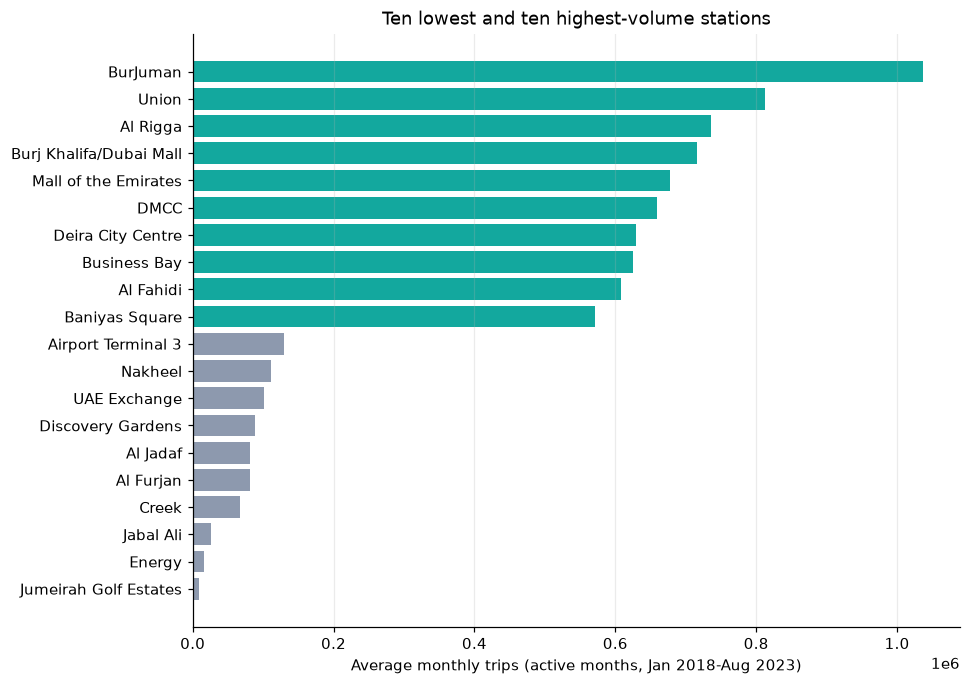

In [38]:
avg = model.groupby("metro_station").trips.mean().sort_values(); avg.index = [i.replace(" Metro Station", "") for i in avg.index]
sel = pd.concat([avg.head(10), avg.tail(10)])
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(sel.index, sel.values, color=[GREY]*10 + [TEAL]*10); ax.grid(axis="y", visible=False)
ax.set(xlabel="Average monthly trips (active months, Jan 2018-Aug 2023)", title="Ten lowest and ten highest-volume stations")
save_fig(fig, "Figure 5.6", "top_bottom_stations")

### Figure 5.7 - ACF/PACF for BurJuman
Row 1 reproduces the notebook 04 cell 7; row 2 repeats it after seasonal differencing (lag 12), which is what the seasonal terms in the candidate models act on.

saved ..\docs\Evidence\ch5\figures\Figure_5.7_acf_pacf_burjuman.png


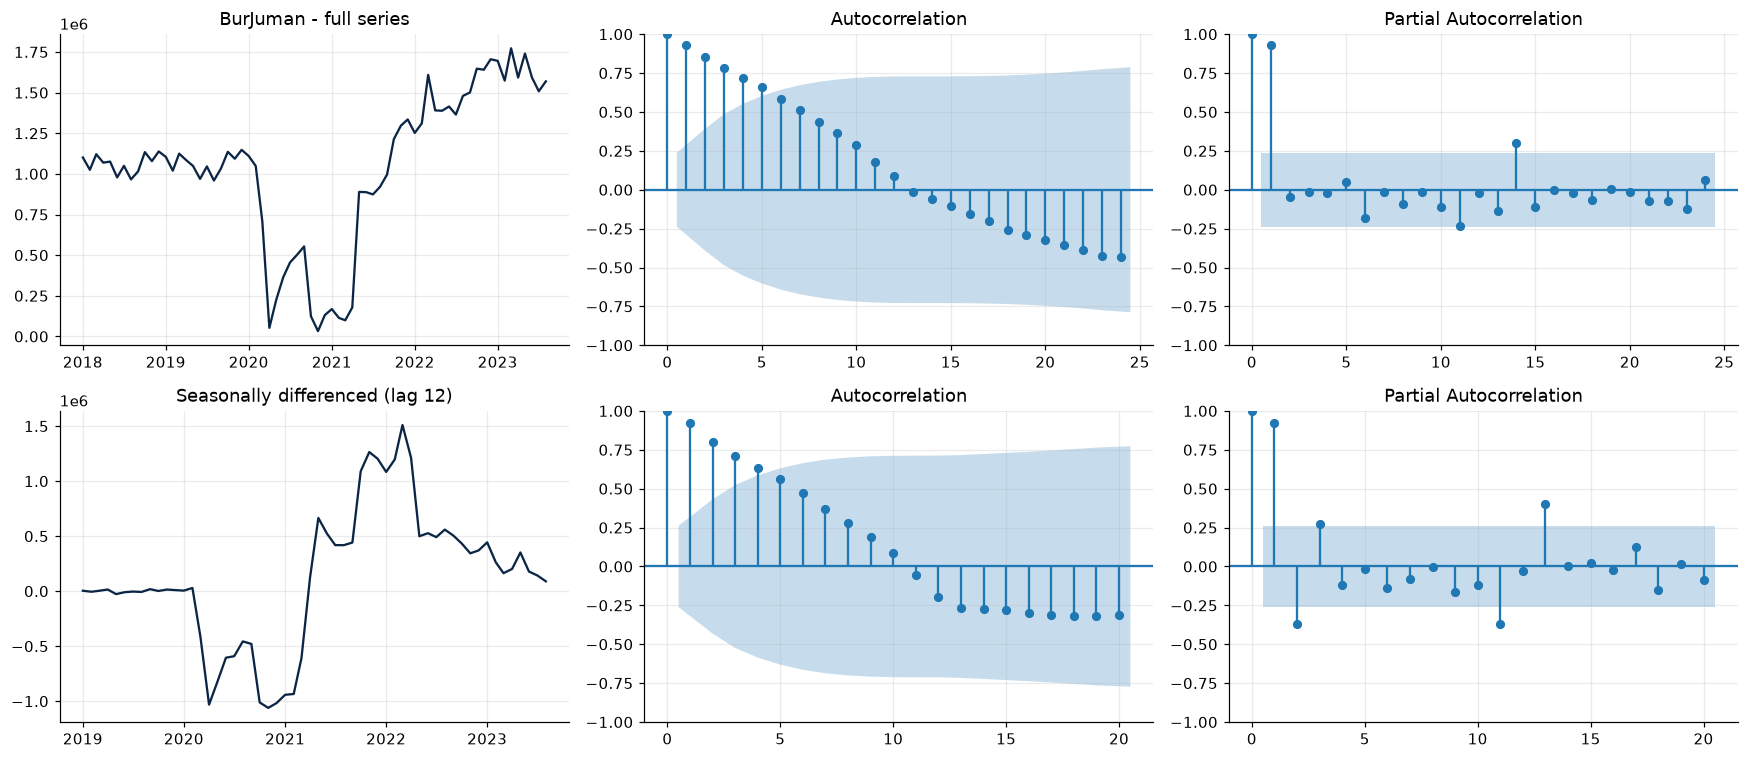

In [39]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
s = get_series("BurJuman"); sd = s.diff(12).dropna()
fig, ax = plt.subplots(2, 3, figsize=(16, 7))
ax[0, 0].plot(s.index, s.values, c=NAVY); ax[0, 0].set_title("BurJuman - full series")
plot_acf(s, lags=24, ax=ax[0, 1]); plot_pacf(s, lags=24, ax=ax[0, 2], method="ywm")
ax[1, 0].plot(sd.index, sd.values, c=NAVY); ax[1, 0].set_title("Seasonally differenced (lag 12)")
plot_acf(sd, lags=20, ax=ax[1, 1]); plot_pacf(sd, lags=20, ax=ax[1, 2], method="ywm")
fig.tight_layout(); save_fig(fig, "Figure 5.7", "acf_pacf_burjuman")

### Figures 5.8 and 5.9 - SARIMA forecast vs actual, and model summary


Selected: (1, 1, 1) (0, 0, 0, 12) | reported MAPE: 4.76
saved ..\docs\Evidence\ch5\figures\Figure_5.8_sarima_forecast_vs_actual.png


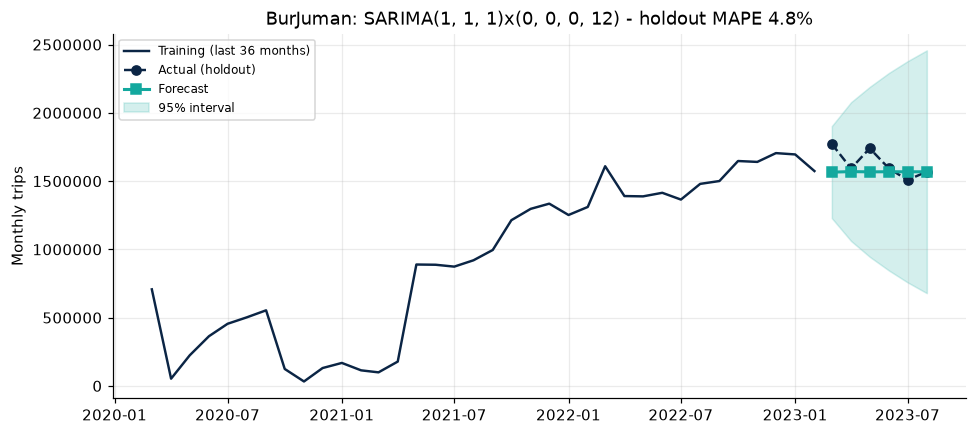

In [40]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
def sarima_holdout(series, order, seasonal_order, h=HOLDOUT):
    train, test = series.iloc[:-h], series.iloc[-h:]
    res = SARIMAX(train, order=order, seasonal_order=seasonal_order, enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    fc = res.get_forecast(h); return train, test, fc.predicted_mean, fc.conf_int()

def plot_forecast(train, test, fc, ci, title, label, slug, colour=TEAL):
    fig, ax = plt.subplots(figsize=(10, 4.3))
    ax.plot(train.index[-36:], train.values[-36:], c=NAVY, lw=1.6, label="Training (last 36 months)")
    ax.plot(test.index, test.values, c=NAVY, lw=1.6, ls="--", marker="o", label="Actual (holdout)")
    ax.plot(fc.index, fc.values, c=colour, lw=2, marker="s", label="Forecast")
    if ci is not None: ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color=colour, alpha=.18, label="95% interval")
    ax.set(title=f"{title} - holdout MAPE {mape(test, fc):.1f}%", ylabel="Monthly trips"); ax.legend(fontsize=8); ax.ticklabel_format(axis="y", style="plain")
    save_fig(fig, label, slug)

STATION = "BurJuman Metro Station"
row = sar[sar.station == STATION].iloc[0]; ORDER, SEAS = ast.literal_eval(row.order), ast.literal_eval(row.seasonal_order)
print("Selected:", ORDER, SEAS, "| reported MAPE:", round(row.MAPE_sarima, 2))
tr, te, fc, ci = sarima_holdout(get_series("BurJuman"), ORDER, SEAS)
plot_forecast(tr, te, fc, ci, f"BurJuman: SARIMA{ORDER}x{SEAS}", "Figure 5.8", "sarima_forecast_vs_actual")

saved ..\docs\Evidence\ch5\figures\Figure_5.9_sarima_model_summary.png


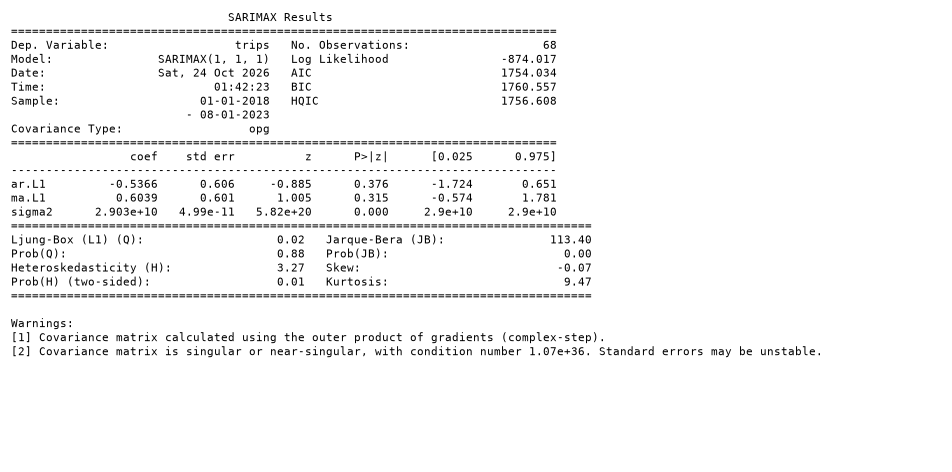

In [41]:
def text_to_image(text, label, slug, fs=7.5):
    lines = text.splitlines(); h = max(2, .17 * len(lines) + .4)
    fig = plt.figure(figsize=(9.5, h)); fig.patch.set_facecolor("white")
    fig.text(.01, .99, text, family="monospace", fontsize=fs, va="top"); plt.axis("off"); save_fig(fig, label, slug)
with open(SARIMA_DIR/f"{safe(STATION)}.pkl", "rb") as f: fitted = pickle.load(f)
text_to_image(fitted.summary().as_text(), "Figure 5.9", "sarima_model_summary")

### Figures 5.10 - 5.13 - LSTM
**Figure 5.10 (architecture diagram)** 

saved ..\docs\Evidence\ch5\figures\Figure_5.10_lstm_architecture.png


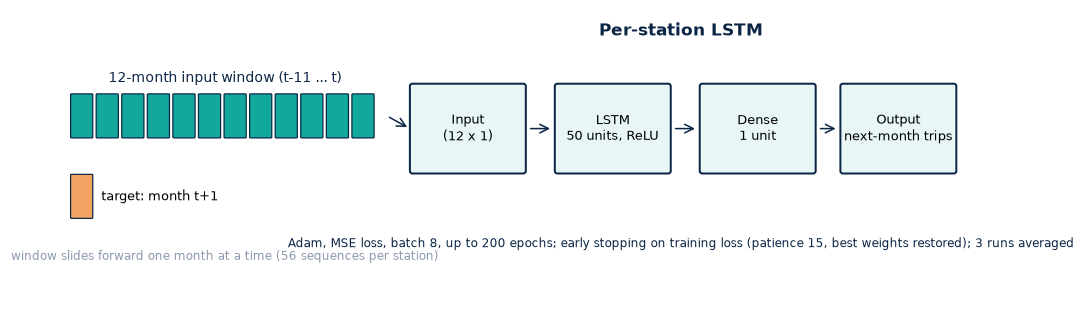

In [42]:
fig, ax = plt.subplots(figsize=(11, 3.4)); ax.axis("off"); ax.set_xlim(0, 11); ax.set_ylim(0, 3.4)
for i in range(12): ax.add_patch(FancyBboxPatch((.25 + i*.3, 1.9), .24, .5, boxstyle="round,pad=0.01", fc=TEAL, ec=NAVY, lw=.8))
ax.text(2.05, 2.55, "12-month input window (t-11 ... t)", ha="center", fontsize=9, color=NAVY)
ax.add_patch(FancyBboxPatch((.25, .95), .24, .5, boxstyle="round,pad=0.01", fc=AMBER, ec=NAVY, lw=.8)); ax.text(.6, 1.2, "target: month t+1", va="center", fontsize=8.5)
ax.text(2.05, .45, "window slides forward one month at a time (56 sequences per station)", ha="center", fontsize=8, color=GREY)
xs = [4.9, 6.6, 8.3, 9.95]
for t, x0 in zip(["Input\n(12 x 1)", "LSTM\n50 units, ReLU", "Dense\n1 unit", "Output\nnext-month trips"], xs):
    ax.add_patch(FancyBboxPatch((x0 - .65, 1.5), 1.3, 1.0, boxstyle="round,pad=0.03", fc="#E8F6F5", ec=NAVY, lw=1.3)); ax.text(x0, 2.0, t, ha="center", va="center", fontsize=8.5)
ax.add_patch(FancyArrowPatch((3.95, 2.15), (4.22, 2.0), arrowstyle="->", mutation_scale=14, color=NAVY))
for a, b in zip(xs[:-1], xs[1:]): ax.add_patch(FancyArrowPatch((a + .7, 2.0), (b - .7, 2.0), arrowstyle="->", mutation_scale=14, color=NAVY))
ax.text(7.4, .6, "Adam, MSE loss, batch 8, up to 200 epochs; early stopping on training loss (patience 15, best weights restored); 3 runs averaged", ha="center", fontsize=8, color=NAVY)
ax.text(7.4, 3.1, "Per-station LSTM", ha="center", fontsize=11, weight="bold", color=NAVY)
save_fig(fig, "Figure 5.10", "lstm_architecture")

In [43]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import MinMaxScaler
SEED = None      # e.g. 42 for a reproducible figure; None = same as your notebooks

def make_sequences(data, window=WINDOW):
    X, y = [], []
    for i in range(len(data) - window): X.append(data[i:i+window]); y.append(data[i+window])
    return np.array(X), np.array(y)
def new_model():
    m = Sequential([LSTM(50, activation="relu", input_shape=(WINDOW, 1)), Dense(1)]); m.compile(optimizer="adam", loss="mse"); return m

def lstm_asrun(series, n_runs=3, epochs=200, validation_split=0.0, monitor="loss"):
    scaler = MinMaxScaler(); scaled = scaler.fit_transform(series.values.reshape(-1, 1))     # fitted on FULL series (as run)
    X, y = make_sequences(scaled); Xtr, ytr, Xte, yte = X[:-HOLDOUT], y[:-HOLDOUT], X[-HOLDOUT:], y[-HOLDOUT:]
    actual = scaler.inverse_transform(yte).flatten(); runs, hist = [], None
    for r in range(n_runs):
        if SEED is not None: tf.keras.utils.set_random_seed(SEED + r)
        m = new_model()
        hist = m.fit(Xtr, ytr, epochs=epochs, batch_size=8, verbose=0, validation_split=validation_split,
                     callbacks=[EarlyStopping(monitor=monitor, patience=15, restore_best_weights=True)])
        runs.append(scaler.inverse_transform(m.predict(Xte, verbose=0)).flatten())
    pred = np.mean(runs, axis=0); idx = series.index[-HOLDOUT:]
    return dict(index=idx, actual=actual, runs=runs, pred=pred, mape=mape(actual, pred), hist=hist, train=series.iloc[:-HOLDOUT])
res_b = lstm_asrun(get_series("BurJuman"))
print(f"BurJuman LSTM (as run, 3-run average): MAPE {res_b['mape']:.1f}%  | per-run:", [round(mape(res_b['actual'], p), 1) for p in res_b['runs']], "| notebooks reported 8.5 / 9.7")

BurJuman LSTM (as run, 3-run average): MAPE 17.9%  | per-run: [12.7, 22.1, 19.5] | notebooks reported 8.5 / 9.7


**Figure 5.11 - training vs validation loss.** 
Left: the training-loss curve under the exact protocol. Right: an illustrative re-run with a chronological 15% validation split (clearly labelled as illustrative in the caption).

saved ..\docs\Evidence\ch5\figures\Figure_5.11_lstm_loss_curves.png


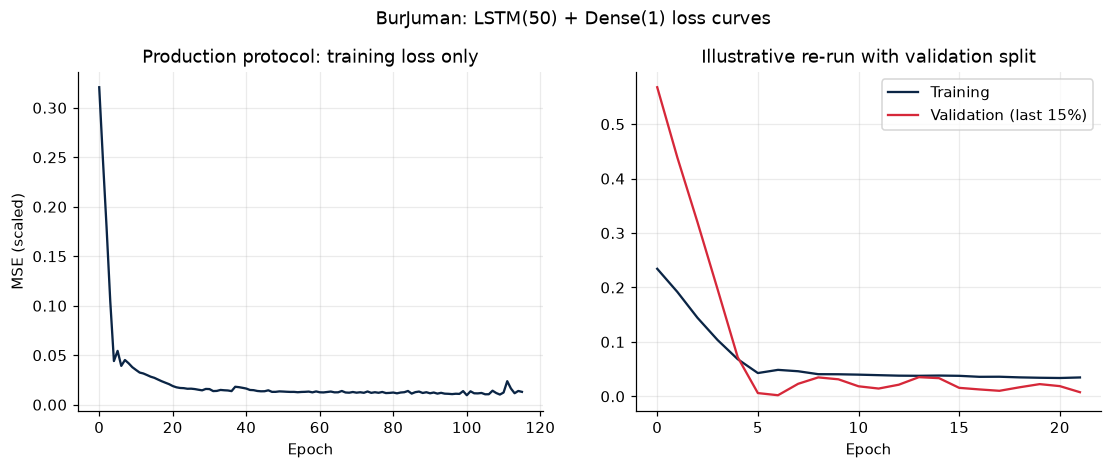

In [44]:
h_prod = res_b["hist"].history["loss"]
SEED_BAK = SEED; r_val = lstm_asrun(get_series("BurJuman"), n_runs=1, validation_split=.15, monitor="val_loss")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h_prod, c=NAVY); ax[0].set(title="Production protocol: training loss only", xlabel="Epoch", ylabel="MSE (scaled)")
ax[1].plot(r_val["hist"].history["loss"], c=NAVY, label="Training"); ax[1].plot(r_val["hist"].history["val_loss"], c=RED, label="Validation (last 15%)")
ax[1].set(title="Illustrative re-run with validation split", xlabel="Epoch"); ax[1].legend()
fig.suptitle("BurJuman: LSTM(50) + Dense(1) loss curves", y=1.02); save_fig(fig, "Figure 5.11", "lstm_loss_curves")

**Figure 5.12 - LSTM forecast vs actual** (one-step-ahead on holdout windows, exactly as evaluated) and **Figure 5.13 - Keras model summary** (loaded from saved `.keras` model).

saved ..\docs\Evidence\ch5\figures\Figure_5.12_lstm_forecast_vs_actual.png


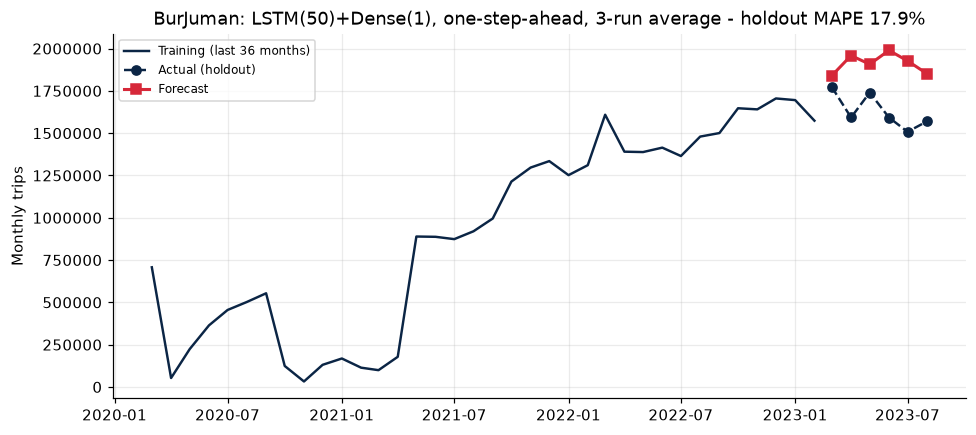

saved ..\docs\Evidence\ch5\figures\Figure_5.13_lstm_model_summary.png


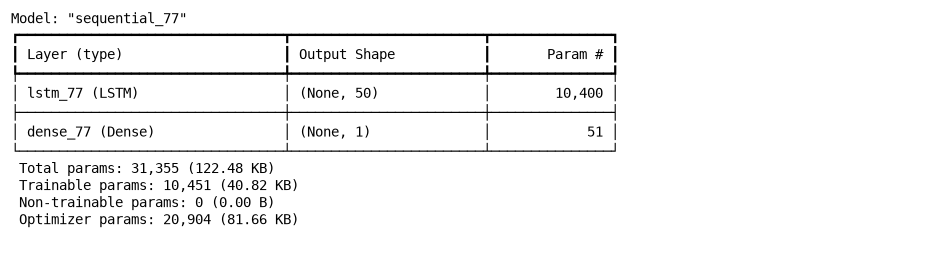

In [45]:
from tensorflow.keras.models import load_model
plot_forecast(res_b["train"], pd.Series(res_b["actual"], index=res_b["index"]), pd.Series(res_b["pred"], index=res_b["index"]), None,
              "BurJuman: LSTM(50)+Dense(1), one-step-ahead, 3-run average", "Figure 5.12", "lstm_forecast_vs_actual", colour=RED)
km = load_model(LSTM_DIR/f"{safe(STATION)}.keras"); lines = []; km.summary(print_fn=lambda s_: lines.append(s_))
text_to_image("\n".join(lines), "Figure 5.13", "lstm_model_summary", fs=9)

### Diagnostic and audit cells (evidence for the critical-discussion section)
**1. EXPO and Energy diagnostic.** Table 5.9 currently has no verified cause for EXPO. 
Actual vs predicted holdout values 

In [46]:
for nm in ["EXPO", "Energy"]:
    rr = lstm_asrun(get_series(nm))
    print(f"\n{full_name(nm)}: MAPE {rr['mape']:.1f}%")
    print(pd.DataFrame({"actual": rr["actual"].round(0), "predicted": rr["pred"].round(0), "pct_error": (np.abs(rr["actual"]-rr["pred"])/rr["actual"]*100).round(0)}, index=rr["index"].strftime("%Y-%m")).to_string())
    print("series min/max used by the scaler:", f"{get_series(nm).min():,.0f} / {get_series(nm).max():,.0f}")


EXPO Metro Station: MAPE 442.1%
           actual  predicted  pct_error
date                                   
2023-03  122235.0   199775.0       63.0
2023-04  114182.0   462440.0      305.0
2023-05  111334.0   480957.0      332.0
2023-06   91479.0   513559.0      461.0
2023-07   61673.0   537065.0      771.0
2023-08   66603.0   546029.0      720.0
series min/max used by the scaler: 5 / 2,275,405

Energy Metro Station: MAPE 106.2%
          actual  predicted  pct_error
date                                  
2023-03  40899.0    53212.0       30.0
2023-04  51805.0    59572.0       15.0
2023-05  36140.0    70744.0       96.0
2023-06  38919.0    76841.0       97.0
2023-07  31376.0    88184.0      181.0
2023-08  30621.0    97268.0      218.0
series min/max used by the scaler: 845 / 51,805


**1b. Testing the ramp-up explanation for EXPO (and the drift at Energy).** Hypothesis: post-collapse EXPO windows sit at a low level that, in training, preceded the opening ramp-up, so the network learned "low level -> large growth". Test 1: among training sequences whose last input is at or below the holdout level, how often was the next month higher? Test 2: feed the trained network flat windows at each level; a ratio near 1 is neutral, well above 1 is a growth bias. BurJuman is the control.

saved ..\docs\Evidence\ch5\figures\Figure_A1_lstm_growth_bias_test.png


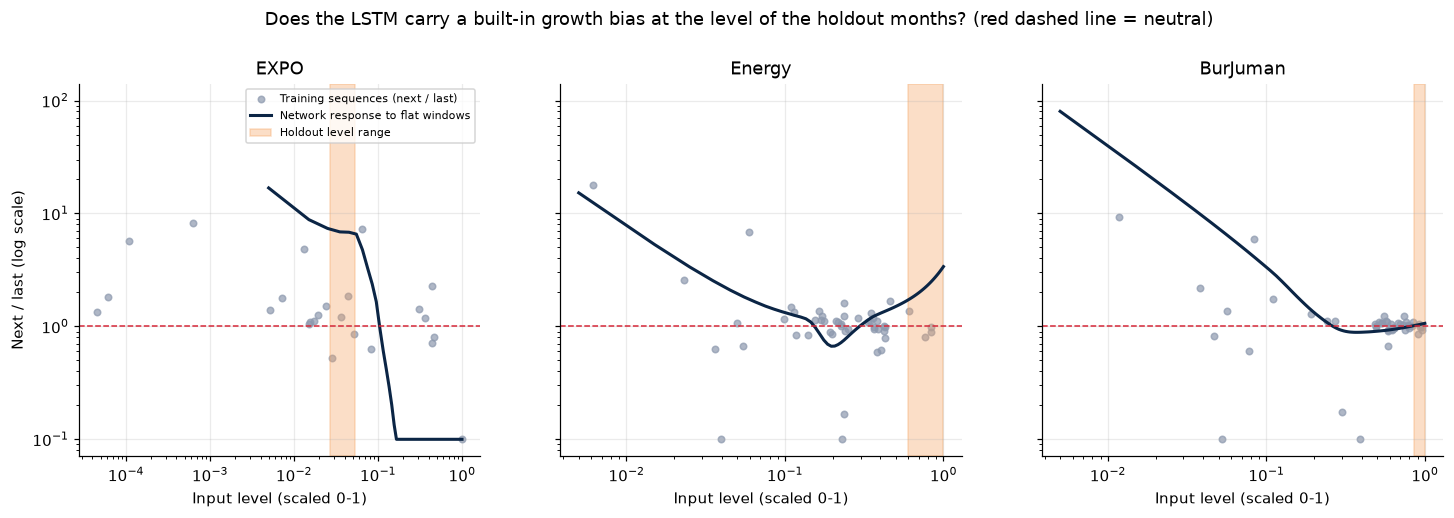

                                                                                                                              0                                                                                         1                                                                                        2
station                                                                                                      EXPO Metro Station                                                                      Energy Metro Station                                                                   BurJuman Metro Station
holdout_level_range                                                                                              (0.027, 0.054)                                                                              (0.599, 1.0)                                                                             (0.848, 1.0)
n_train_low                                                                    

In [48]:
def train_asrun_model(series, epochs=200):
    scaler = MinMaxScaler(); scaled = scaler.fit_transform(series.values.reshape(-1, 1))      # as run: full-series scaler
    X, y = make_sequences(scaled); Xtr, ytr, Xte, yte = X[:-HOLDOUT], y[:-HOLDOUT], X[-HOLDOUT:], y[-HOLDOUT:]
    if SEED is not None: tf.keras.utils.set_random_seed(SEED)
    m = new_model()
    m.fit(Xtr, ytr, epochs=epochs, batch_size=8, verbose=0, callbacks=[EarlyStopping(monitor="loss", patience=15, restore_best_weights=True)])
    return m, Xtr, ytr, Xte, yte

def analyse_levels(name, models, Xtr, ytr, Xte, yte, ax=None):
    last_tr, last_te = Xtr[:, -1, 0], Xte[:, -1, 0]
    ratio_tr = ytr[:, 0] / np.maximum(last_tr, 1e-6)
    low = last_tr <= 1.5 * last_te.max()                      # training windows at or below the holdout level
    pred_te = np.mean([m.predict(Xte, verbose=0)[:, 0] for m in models], axis=0)
    levels = np.linspace(0.005, 1.0, 100)
    flat = np.repeat(levels[:, None, None], WINDOW, axis=1)
    resp = np.mean([m.predict(flat, verbose=0)[:, 0] for m in models], axis=0) / levels
    band = (levels >= last_te.min()) & (levels <= last_te.max())
    if not band.any(): band = np.zeros_like(levels, bool); band[np.argmin(abs(levels - last_te.mean()))] = True
    r = dict(station=name, holdout_level_range=(round(float(last_te.min()), 3), round(float(last_te.max()), 3)),
             n_train_low=int(low.sum()),
             share_followed_by_rise=round(float((ytr[low, 0] > last_tr[low]).mean()), 2) if low.any() else np.nan,
             median_train_next_over_last=round(float(np.median(ratio_tr[low])), 2) if low.any() else np.nan,
             median_holdout_pred_over_last=round(float(np.median(pred_te / np.maximum(last_te, 1e-6))), 2),
             median_flat_response_at_holdout_level=round(float(np.median(resp[band])), 2),
             max_scaled_prediction=round(float(pred_te.max()), 2))
    if ax is not None:
        ax.scatter(last_tr, np.clip(ratio_tr, .1, 100), s=18, c=GREY, alpha=.7, label="Training sequences (next / last)")
        ax.plot(levels, np.clip(resp, .1, 100), c=NAVY, lw=2, label="Network response to flat windows")
        ax.axvspan(last_te.min(), last_te.max(), color=AMBER, alpha=.35, label="Holdout level range")
        ax.axhline(1, c=RED, ls="--", lw=1)
        ax.set(xscale="log", yscale="log", title=name.replace(" Metro Station", ""), xlabel="Input level (scaled 0-1)")
    return r

def verdict(r):
    up_train = r["median_train_next_over_last"] > 1.5
    up_resp = r["median_flat_response_at_holdout_level"] > 1.5
    return ("SUPPORTS growth bias at this level (training ratio and response both > 1.5)" if up_train and up_resp else
            "PARTLY: response > 1.5 but training ratio is not (bias not explained by training growth)" if up_resp else
            "NOT SUPPORTED: network is roughly neutral on flat windows at this level; look elsewhere")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True); rows = []
for ax, nm in zip(axes, ["EXPO", "Energy", "BurJuman"]):
    s_ = get_series(nm); trained = [train_asrun_model(s_) for _ in range(3)]
    ms_ = [t[0] for t in trained]; _, Xtr_, ytr_, Xte_, yte_ = trained[0]
    rows.append(analyse_levels(full_name(nm), ms_, Xtr_, ytr_, Xte_, yte_, ax))
    rows[-1]["verdict"] = verdict(rows[-1])
axes[0].set_ylabel("Next / last (log scale)"); axes[0].legend(fontsize=7, loc="upper right")
fig.suptitle("Does the LSTM carry a built-in growth bias at the level of the holdout months? (red dashed line = neutral)", y=1.03)
save_fig(fig, "Figure A1", "lstm_growth_bias_test")
diag = pd.DataFrame(rows); pd.set_option("display.max_colwidth", 120); print(diag.T.to_string())

**2. Like-for-like protocol audit.** Compares three LSTM protocols against the SARIMA holdout MAPE: **(a)** as run (one-step, scaler on full series); **(b)** one-step with the scaler fitted on the training part only (removes leakage); **(c)** recursive six-step forecast from the end of training with the scaler on training only (the same task SARIMA was given). 

In [49]:
def lstm_variant(series, scaler_on="train", recursive=False, n_runs=3, epochs=200):
    train = series.iloc[:-HOLDOUT]; test = series.iloc[-HOLDOUT:]
    sc = MinMaxScaler().fit((train if scaler_on == "train" else series).values.reshape(-1, 1))
    z = sc.transform(series.values.reshape(-1, 1)); ztr = sc.transform(train.values.reshape(-1, 1))
    Xtr, ytr = make_sequences(ztr); runs = []
    for r in range(n_runs):
        if SEED is not None: tf.keras.utils.set_random_seed(SEED + r)
        m = new_model(); m.fit(Xtr, ytr, epochs=epochs, batch_size=8, verbose=0, callbacks=[EarlyStopping(monitor="loss", patience=15, restore_best_weights=True)])
        if recursive:
            win = list(ztr[-WINDOW:, 0]); out = []
            for _ in range(HOLDOUT):
                p = float(m.predict(np.array(win[-WINDOW:]).reshape(1, WINDOW, 1), verbose=0)[0, 0]); out.append(p); win.append(p)
            runs.append(sc.inverse_transform(np.array(out).reshape(-1, 1)).flatten())
        else:
            Xall, _ = make_sequences(z); runs.append(sc.inverse_transform(m.predict(Xall[-HOLDOUT:], verbose=0)).flatten())
    return mape(test.values, np.mean(runs, axis=0))

AUDIT = ["BurJuman", "Etisalat", "Ibn Battuta", "World Trade Centre", "Energy", "Union"]     
rows = []
for nm in AUDIT:
    fn = full_name(nm); s_ = get_series(nm)
    rows.append([fn.replace(" Metro Station", ""), round(comp.loc[comp.station == fn, "MAPE_sarima"].iloc[0], 1),
                 round(lstm_variant(s_, "full", False), 1), round(lstm_variant(s_, "train", False), 1), round(lstm_variant(s_, "train", True), 1)])
    print(rows[-1])
t510 = pd.DataFrame(rows, columns=["Station", "SARIMA (6-step)", "LSTM (a) as run", "LSTM (b) train-only scaler", "LSTM (c) recursive 6-step"])
save_table(t510, "Table 5.7", "lstm_protocol_audit"); t510

['BurJuman', np.float64(4.8), 12.6, 11.7, 39.4]
['Etisalat', np.float64(7.9), 5.0, 6.2, 8.4]
['Ibn Battuta', np.float64(9.6), 11.1, 7.6, 11.7]
['World Trade Centre', np.float64(10.7), 27.1, 32.0, 53.3]
['Energy', np.float64(14.2), 87.5, 67.3, 257.7]
['Union', np.float64(5.4), 12.7, 18.5, 34.1]
saved Table_5.7_lstm_protocol_audit


,Station,SARIMA (6-step),LSTM (a) as run,LSTM (b) train-only scaler,LSTM (c) recursive 6-step
0,BurJuman,4.8,12.6,11.7,39.4
1,Etisalat,7.9,5.0,6.2,8.4
2,Ibn Battuta,9.6,11.1,7.6,11.7
3,World Trade Centre,10.7,27.1,32.0,53.3
4,Energy,14.2,87.5,67.3,257.7
5,Union,5.4,12.7,18.5,34.1


### EXPO structural break 

saved ..\docs\Evidence\ch5\figures\Figure_5.14_expo_structural_break.png


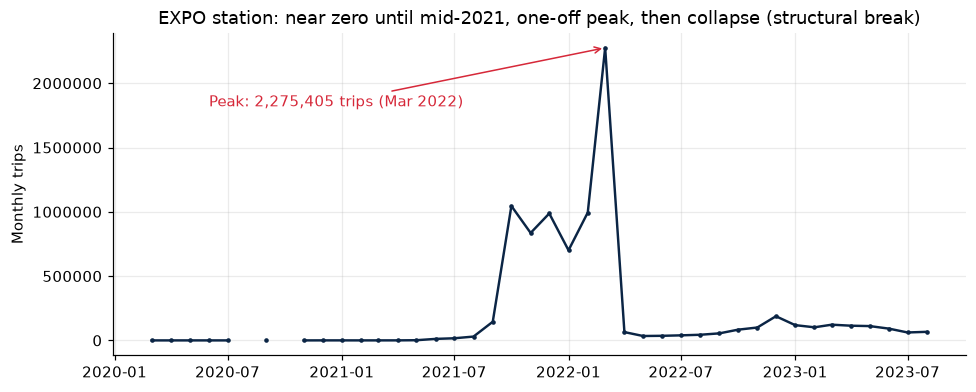

In [51]:
expo = get_series("EXPO", clean=False)
fig, ax = plt.subplots(figsize=(10, 3.8)); ax.plot(expo.index, expo.values, c=NAVY, lw=1.6, marker=".", ms=4)
pk = expo.idxmax(); ax.annotate(f"Peak: {expo.max():,.0f} trips ({pk:%b %Y})", xy=(pk, expo.max()), xytext=(pd.Timestamp("2020-06-01"), expo.max()*.8),
            arrowprops=dict(arrowstyle="->", color=RED), color=RED)
ax.set(title="EXPO station: near zero until mid-2021, one-off peak, then collapse (structural break)", ylabel="Monthly trips"); ax.ticklabel_format(axis="y", style="plain")
save_fig(fig, "Figure 5.14", "expo_structural_break")